## Informacje o danych

In [1]:
import pandas as pd

df = pd.read_csv("C:/Users/sylwi/OneDrive/Dokumenty/GitHub/project-telco-churn/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
print(30*"--")
df.info()
print(30*"--")
df.head()

(7043, 21)
------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-n

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print(df["Churn"].value_counts())
print(30*"--")
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
------------------------------------------------------------
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


Churn: $26,5\%$ klientów odeszło. Klasy niezbalansowane, więc accuracy nie będzie dobrą metryką.

In [3]:
print(df["customerID"].nunique()) 

bad = df[pd.to_numeric(df["TotalCharges"], errors = "coerce"). isna()] 
print(len(bad))

bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

7043
11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


TotalCharges trzeba wypełnić zerami. Nie ma sensu usuwać, ponieważ usuniemy dodatkowe dane, a zero to również informacja o statusie klienta.

## Czyszczenie  danych

1. W TotalCharges puste miejsca stają się NaN
2. Te 11 braków to klienci z tenure = 0, czyli łącznie zapłacili 0.
3. customerID to numer bez wartości predykcyjnej
4. Target: Yes/No = 1/0 (1 = odszedł)

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [5]:
print(df.shape)
print(30*"--")
print(df["TotalCharges"].dtype, df["TotalCharges"].isna().sum())
print(30*"--")
print(df["Churn"].value_counts())
print(30*"--")
print(df.isna().sum().sum())

(7043, 20)
------------------------------------------------------------
float64 0
------------------------------------------------------------
Churn
0    5174
1    1869
Name: count, dtype: int64
------------------------------------------------------------
0


In [6]:
df.to_csv("../data/processed/telco_clean.csv", index=False)

## Oglądanie danych

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

**Umowa a churn**
Czy churn zależy od typu umowy?

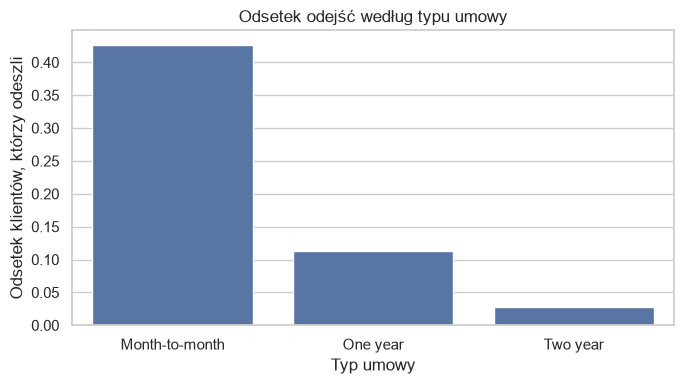

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=df,
    x="Contract",
    y="Churn",
    order=["Month-to-month", "One year", "Two year"],
    errorbar=None,
    ax=ax,
)

ax.set_title("Odsetek odejść według typu umowy")
ax.set_xlabel("Typ umowy")
ax.set_ylabel("Odsetek klientów, którzy odeszli")

plt.tight_layout()
plt.savefig('odsetek_odejsc_wg_umowy.png', dpi=300)
plt.show()

Widać korelację - umowa *'Month-to-month'* wykazuje większy odsetek rezygnujacych klientów, ale jest to również naturalne, ponieważ ten rodzaj umowy pozwala na szybką rezygnację lub rezygnację w dowolnym momencie. Nie daje to natomiast odpowiedzi, jaki faktycznie był okres jej trwania

**Staż a churn**

Czy odchodzą nowi czy starzy klienci?

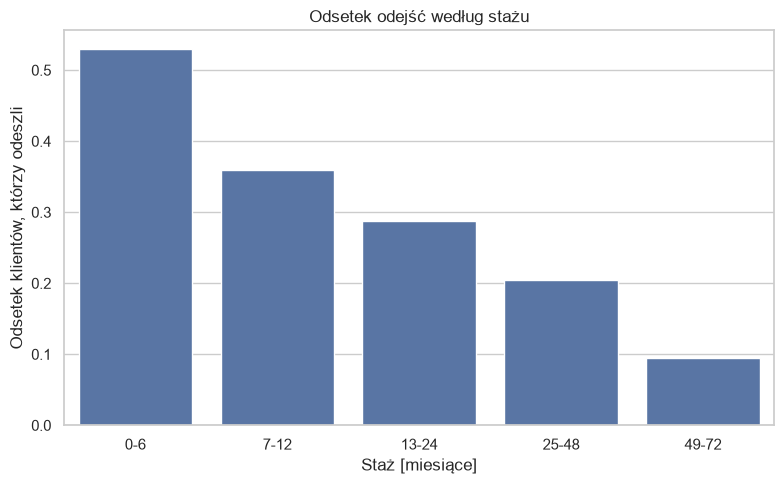

In [9]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=df, 
    x="tenure_group", 
    y="Churn", 
    errorbar=None, 
    ax=ax
)

ax.set_title("Odsetek odejść według stażu")
ax.set_xlabel("Staż [miesiące]")
ax.set_ylabel("Odsetek klientów, którzy odeszli")

plt.tight_layout()
plt.savefig('odestek_odejsc_wg_staz.png', dpi=300)
plt.show()

Najwięcej odejść jest w pierwszych **6 miesiącach** od podpisania umowy, potem sukcesywnie się to zmniejsza.

**Opłata miesięczna a churn**

Czy odchodzący płacą inaczej? Jak rozkładają się wszyscy odchodzący (1869 osób = 100%)

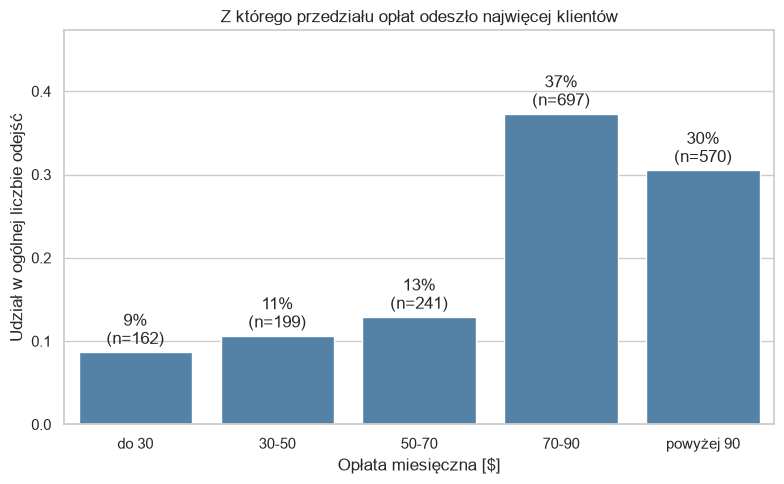

In [10]:
df["charges_group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 30, 50, 70, 90, 120],
    labels=["do 30", "30-50", "50-70", "70-90", "powyżej 90"],
)

churned = df[df["Churn"] == 1]

share = (
    churned["charges_group"]
    .value_counts(normalize=True)
    .sort_index()
    .reset_index()
)
share.columns = ["charges_group", "share"]
counts = churned["charges_group"].value_counts().sort_index().values

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=share, 
    x="charges_group", 
    y="share", 
    color="steelblue", 
    ax=ax
)

for i, (s, n) in enumerate(zip(share["share"], counts)):
    ax.text(i, s + 0.01, f"{s:.0%}\n(n={n})", ha="center")

ax.set_title("Z którego przedziału opłat odeszło najwięcej klientów")
ax.set_xlabel("Opłata miesięczna [$]")
ax.set_ylabel("Udział w ogólnej liczbie odejść")
ax.set_ylim(0, share["share"].max() + 0.1)

plt.tight_layout()
plt.savefig('oplata_a_churn.png', dpi=300)
plt.show()

Najwięcej odeszło z grup 70-90 oraz powyżej 90, odpowiednio 697 i 570 osób ze wszystkich, który odeszli.

**Churn a umowa a opłata miesięczna**

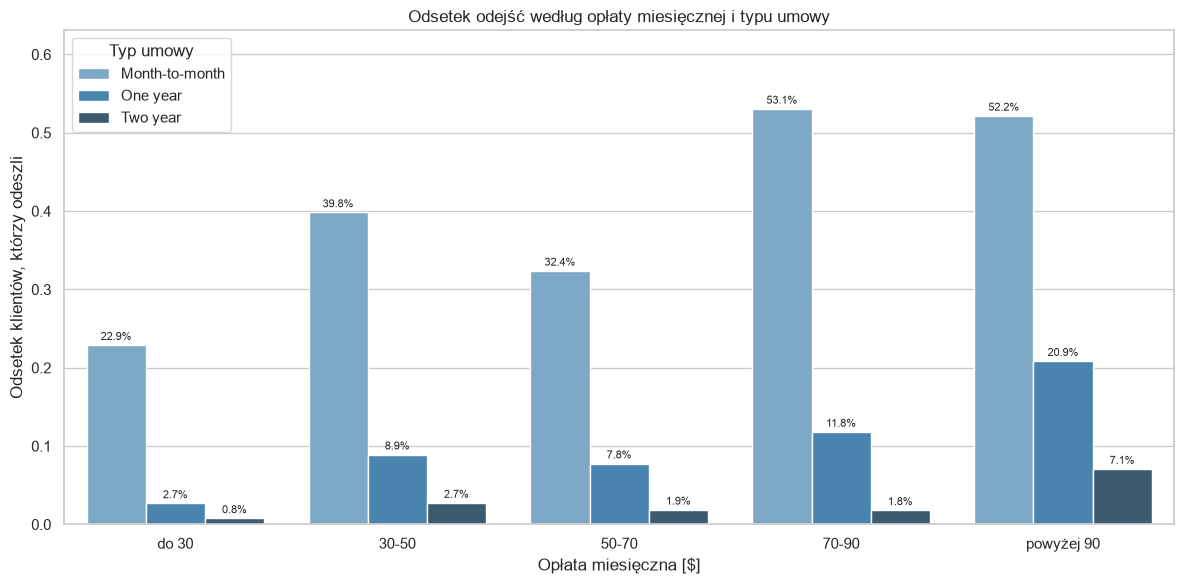

In [11]:
charges_contract_stats = (
    df.groupby(["charges_group", "Contract"], observed=True)["Churn"]
    .agg(churn_rate="mean", n="size")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=charges_contract_stats,
    x="charges_group",
    y="churn_rate",
    hue="Contract",
    hue_order=["Month-to-month", "One year", "Two year"],
    palette="Blues_d",
    ax=ax,
)

for p in ax.patches:
    height = p.get_height()
    if not pd.isna(height) and height > 0:
        ax.annotate(
            f"{height:.1%}",  
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 2),
            textcoords="offset points",
        )

ax.set_title("Odsetek odejść według opłaty miesięcznej i typu umowy")
ax.set_xlabel("Opłata miesięczna [$]")
ax.set_ylabel("Odsetek klientów, którzy odeszli")
ax.set_ylim(0, charges_contract_stats["churn_rate"].max() + 0.1)
ax.legend(title="Typ umowy")

plt.tight_layout()
plt.savefig('churn_oplata_umowa.png', dpi=300)
plt.show()

- *duży odsetek churnu w przedziale 30-50* - umowy krótkoterminowe (jak w każdym przedziale) stanowią najwyższy czynnik ryzyka. Jednocześnie klienci na umowach rocznych ($8,9\%$) i dwuletnich ($2,7\%$) w tej grupie praktycznie nie odchodzą, ale jest ich na tyle mało, że wysoki odsetek Month-to-month podciąga średnią całej grupy w górę. Prawdopodobnie mamy tu przypadek, kiedy klienci nie są przywiązani umowami, więc jeśli oferta przestaje im odpowiadać, rezygnują z niej.
  
- *przedziały 70-90 oraz powyżej 90* - w obu przypadkach dla umów krótkoterminowych mamy odsetek churmu powyżej $50\%$, więc ponad połowa klientów z takimi umowami znajduje się w grupie klientów płacących najwyższe stawki, ale nie została przywiazana umową długoterminową. To grupa generująca najwyższe straty dla firmy, o najwyższym ryzyku chrumu.

**Obciążenia a churn**

Jak sytuacja życiowa klienta (senior, partner, dzieci/osoby na utrzymaniu) oraz z jakich umów korzystają? Czy jest widoczna korelacja między ryzykownymi grupami? Dwa wykresy:

*Pierwszy*: odsetek odejść dla profilu gospodarstwa (kombinacja SeniorCitizen, Partner, Dependents). W etykiecie jest liczebność grupy.


*Drugi*: struktura umów jakie wystepują w wyznaczonych już profilach gospodarstw domowych.

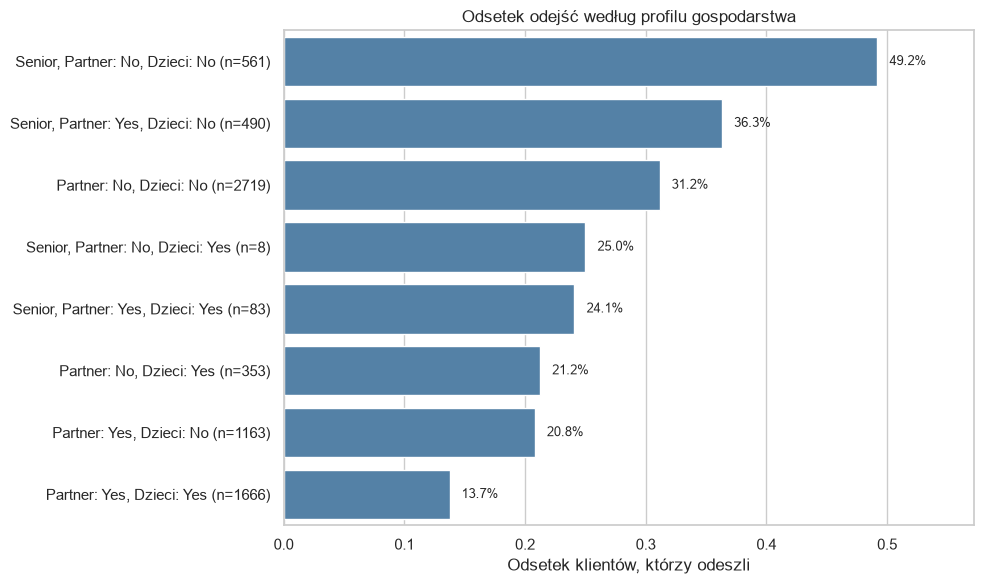

In [12]:
burden = df[["SeniorCitizen", "Partner", "Dependents", "Churn"]].copy()

burden["profile"] = (
    burden["SeniorCitizen"].map({0: "", 1: "Senior, "})
    + "Partner: " + burden["Partner"]
    + ", Dzieci: " + burden["Dependents"]
)

profile_stats = (
    burden.groupby("profile")["Churn"]
    .agg(churn_rate="mean", n="size")
    .sort_values("churn_rate", ascending=False)
    .reset_index()
)
profile_stats["label"] = profile_stats["profile"] + " (n=" + profile_stats["n"].astype(str) + ")"

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(data=profile_stats, y="label", x="churn_rate", color="steelblue", ax=ax)

for i, rate in enumerate(profile_stats["churn_rate"]):
    ax.text(rate + 0.01, i, f"{rate:.1%}", va="center", fontsize=9)

ax.set_title("Odsetek odejść według profilu gospodarstwa")
ax.set_xlabel("Odsetek klientów, którzy odeszli")
ax.set_ylabel("")
ax.set_xlim(0, profile_stats["churn_rate"].max() + 0.08)

plt.tight_layout()
plt.savefig('profil_gospodarstwa_a_churn.png', dpi=300)
plt.show()

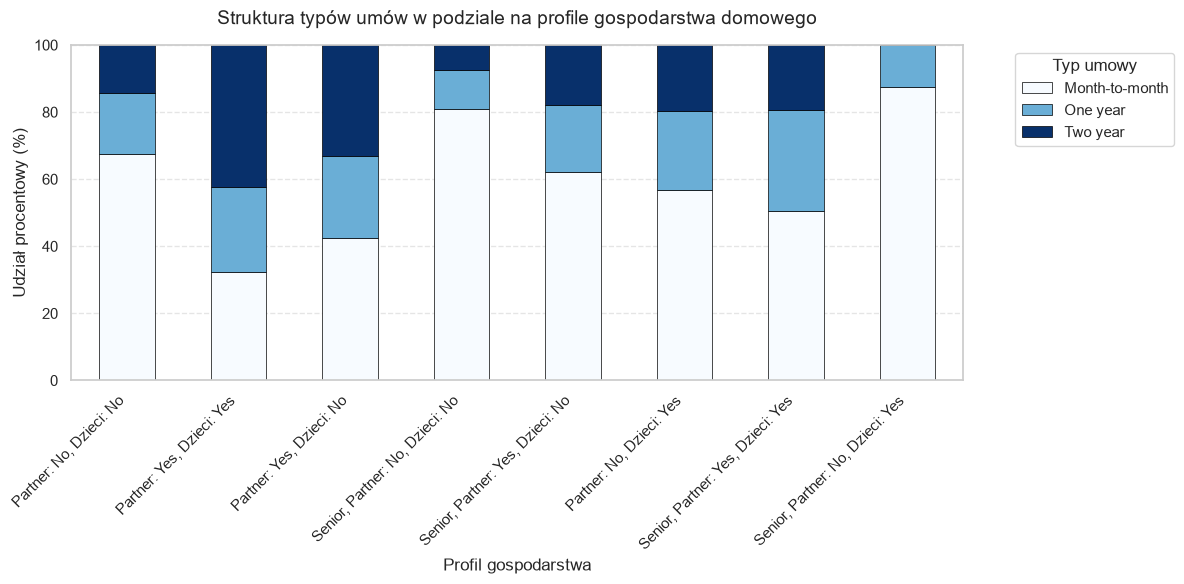

In [13]:
burden = df[["SeniorCitizen", "Partner", "Dependents", "Contract"]].copy()

burden["profile"] = (
    burden["SeniorCitizen"].map({0: "", 1: "Senior, "})
    + "Partner: "
    + burden["Partner"]
    + ", Dzieci: "
    + burden["Dependents"]
)

profile_stats = (
    burden.groupby("profile")
    .size()
    .reset_index(name="n")
    .sort_values("n", ascending=False)
)

profile_contract = (
    pd.crosstab(burden["profile"], burden["Contract"], normalize="index") * 100
)
profile_contract = profile_contract.loc[profile_stats["profile"]]

fig, ax = plt.subplots(figsize=(12, 6))
profile_contract.plot(
    kind="bar",
    stacked=True,
    colormap="Blues",
    edgecolor="black",
    linewidth=0.5,
    ax=ax,
)

plt.title(
    "Struktura typów umów w podziale na profile gospodarstwa domowego",
    fontsize=14,
    pad=15,
)
plt.xlabel("Profil gospodarstwa", fontsize=12)
plt.ylabel("Udział procentowy (%)", fontsize=12)
plt.legend(title="Typ umowy", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig('profil_gospodarstwa_a_umowy.png', dpi=300)
plt.show()

Najwyższy jest u samotnych seniorów bez dzieci ($49,2%$, n=561), potem senior z partnerem bez dzieci ($36,3%$). Osoby niebędące seniorami, samotne i bez dzieci mają $31,2%$. Najstabilniejsi są klienci z partnerem i dziećmi, niebędący seniorami ($13,7%$, n=1666). Warto pamiętać, że w danych nie ma informacji, ile odejść wśród seniorów wynika ze zgonów.

Należy zwrócić uwagę, że we wskazanych gospodarstwach dominują umowy krótkoterminowe.

#### **Odsetek odejść a liczba posiadanych produktów**

Czy im więcej produktów i wyższe koszta, tym wyższa szansa na churn?

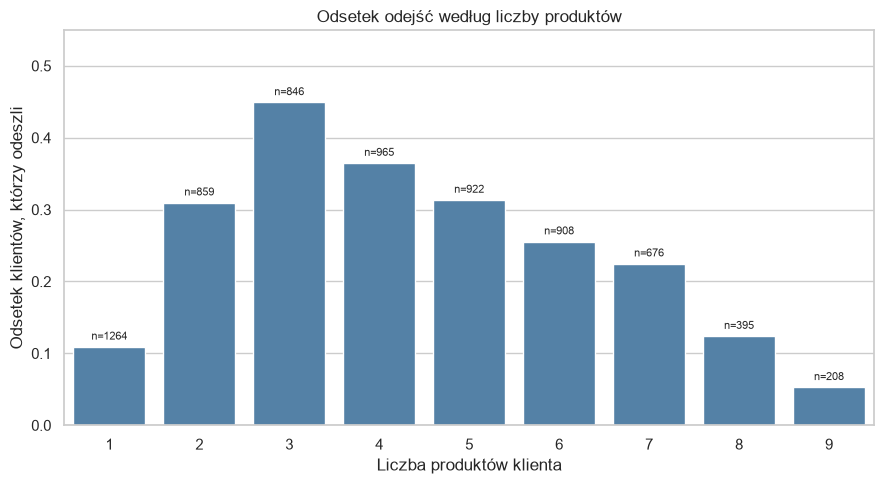

In [14]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]

df["n_products"] = (
    df["PhoneService"].eq("Yes").astype(int)
    + df["InternetService"].ne("No").astype(int)
    + df["MultipleLines"].eq("Yes").astype(int)
    + sum(df[c].eq("Yes").astype(int) for c in addons)
)

by_count = (
    df.groupby("n_products")["Churn"]
    .agg(churn_rate="mean", n="size")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(data=by_count, x="n_products", y="churn_rate",
            color="steelblue", ax=ax)
for i, row in by_count.iterrows():
    ax.text(i, row["churn_rate"] + 0.01, f"n={int(row['n'])}", ha="center", fontsize=8)

ax.set_title("Odsetek odejść według liczby produktów")
ax.set_xlabel("Liczba produktów klienta")
ax.set_ylabel("Odsetek klientów, którzy odeszli")
ax.set_ylim(0, by_count["churn_rate"].max() + 0.1)

plt.tight_layout()
plt.savefig('produkty_ilosc_churn.png', dpi=300)
plt.show()

**Największy odsetek występuje u klientów posiadających umiarkowaną liczbę usług (najwięcej przy 3 usługach), najmniej osoby z 9 produktami.** Nistkie zagrożenie to również osoby z 1 usluga oraz 8 usługami. Hipoteza - im więcej produktów, tym korzystniejsze pakiety i większe przywiązanie. Dlaczego odsetek churnu najwyższy jest dla średnich grup? To potencjalni klienci do rozszerzenia, więc dlaczego jest taki odsetek odejść?

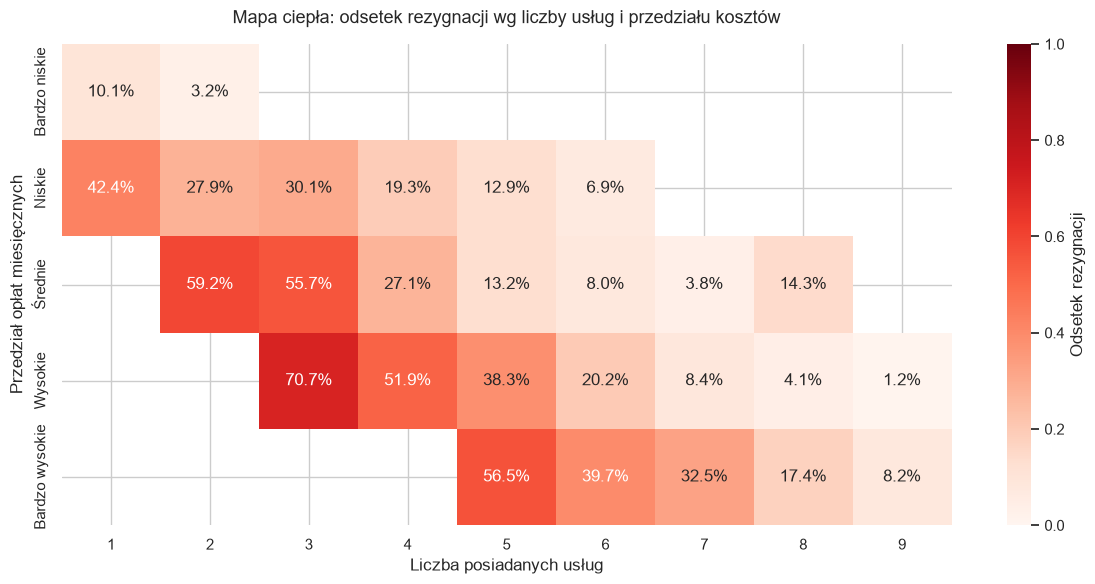

In [15]:
df["charge_bin"] = pd.qcut(
    df["MonthlyCharges"],
    q=5,
    labels=["Bardzo niskie", "Niskie", "Średnie", "Wysokie", "Bardzo wysokie"],
)

pivot_table = df.pivot_table(
    values="Churn",
    index="charge_bin",
    columns="n_products",
    aggfunc="mean",  
    observed=True,
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Odsetek rezygnacji"},
)

plt.title("Mapa ciepła: odsetek rezygnacji wg liczby usług i przedziału kosztów", fontsize=13, pad=15)
plt.xlabel("Liczba posiadanych usług", fontsize=12)
plt.ylabel("Przedział opłat miesięcznych", fontsize=12)

plt.tight_layout()
plt.savefig('produkty_koszt_heatmap.png', dpi=300)
plt.show()

Ekstremalnie wysoki churn (sięgający od $51.9\%$ do aż $70.7\%$) koncentruje się u klientów, którzy posiadają niewielką liczbę usług (2 do 4 produktów), a jednocześnie generują średnie lub wysokie opłaty miesięczne.

Mapa wyraźnie pokazuje, że wysoka cena sama w sobie nie jest głównym powodem odejścia – kluczowy jest stosunek kosztu do liczby otrzymywanych usług. Klienci płacący wysokie kwoty przy dużej liczbie usług (7–9 produktów) wykazują bardzo niski wskaźnik churnu (zaledwie od $1.2\%$ do $32,5\%$).

Hipoteza - klienci z grupy średniej są najbardziej narażeni na churn, szczególnie ci, którzy placą najwyższe koszta, ponieważ posiadają produkt, który stanowi główny składnik tych kosztów i jest powodem rezygnacji (to na bazie tego, że klienci posiadajacy 1 produkt płacą stosunkowo mało, ale już od 2 produktów koszty mogą mocno skoczyc w górę, podobnie churn). Ergo - istnieje produkt, który powoduje oddejścia klientów, potencjalnie jest z zakresu usług internetowych.

In [16]:
service_columns = [
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
]

print('LISTA PRODUKTÓW I USŁUG W ZBIORZE\n')
for col in service_columns:
  unique_vals = df[col].unique().tolist()
  print(f'• Produkt: {col}')
  print(f'  Dostępne warianty: {unique_vals}\n')

LISTA PRODUKTÓW I USŁUG W ZBIORZE

• Produkt: PhoneService
  Dostępne warianty: ['No', 'Yes']

• Produkt: MultipleLines
  Dostępne warianty: ['No phone service', 'No', 'Yes']

• Produkt: InternetService
  Dostępne warianty: ['DSL', 'Fiber optic', 'No']

• Produkt: OnlineSecurity
  Dostępne warianty: ['No', 'Yes', 'No internet service']

• Produkt: OnlineBackup
  Dostępne warianty: ['Yes', 'No', 'No internet service']

• Produkt: DeviceProtection
  Dostępne warianty: ['No', 'Yes', 'No internet service']

• Produkt: TechSupport
  Dostępne warianty: ['No', 'Yes', 'No internet service']

• Produkt: StreamingTV
  Dostępne warianty: ['No', 'Yes', 'No internet service']

• Produkt: StreamingMovies
  Dostępne warianty: ['No', 'Yes', 'No internet service']



Większość produktów, to produkty związane z internetem, należy skupić się na nich w pierwszej kolejności. Założenie - usługi telefoniczne są tańsze, internet i uslugi dodatkowe droższe.

**Churn a uslugi internetowe**

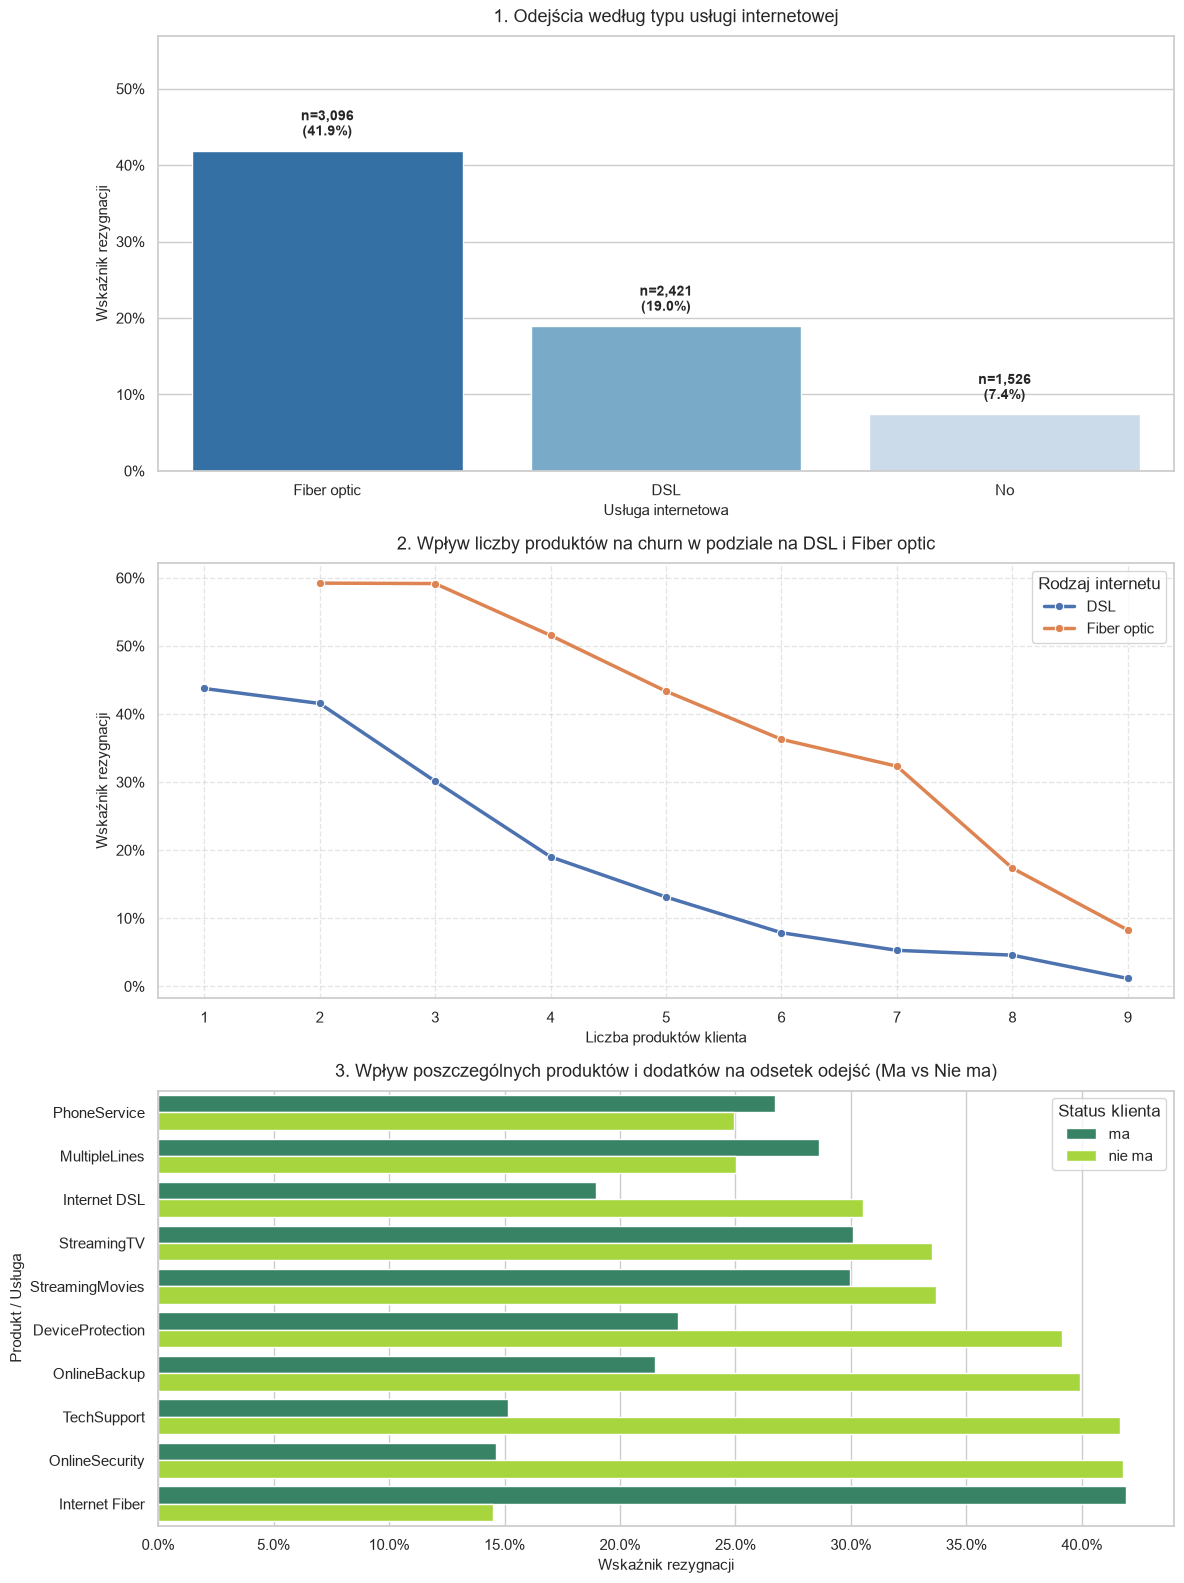

In [17]:
import matplotlib.ticker as ticker

addons = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
]

net_stats = (
    df.groupby('InternetService')['Churn']
    .agg(churn_rate='mean', n='size')
    .sort_values('churn_rate', ascending=False)
    .reset_index()
)

by_internet = (
    df[df['InternetService'] != 'No']
    .groupby(['InternetService', 'n_products'])['Churn']
    .agg(churn_rate='mean', n='size')
    .reset_index()
)
by_internet = by_internet[by_internet['n'] >= 30]

all_rows = pd.Series(True, index=df.index)
has_phone = df['PhoneService'] == 'Yes'
has_net = df['InternetService'] != 'No'

specs = [
    ('PhoneService', df['PhoneService'].eq('Yes'), all_rows),
    ('MultipleLines', df['MultipleLines'].eq('Yes'), has_phone),
    ('Internet DSL', df['InternetService'].eq('DSL'), all_rows),
    ('Internet Fiber', df['InternetService'].eq('Fiber optic'), all_rows),
] + [(c, df[c].eq('Yes'), has_net) for c in addons]

rows = []
for name, has, pop in specs:
  rows.append({
      'produkt': name,
      'grupa': 'ma',
      'churn_rate': df.loc[pop & has, 'Churn'].mean(),
      'n': (pop & has).sum(),
  })
  rows.append({
      'produkt': name,
      'grupa': 'nie ma',
      'churn_rate': df.loc[pop & ~has, 'Churn'].mean(),
      'n': (pop & ~has).sum(),
  })
product_effect = pd.DataFrame(rows)

product_order = (
    product_effect.groupby('produkt')['churn_rate']
    .max()
    .sort_values(ascending=True)
    .index
)

fig, axes = plt.subplots(3, 1, figsize=(12, 16))

sns.barplot(
    data=net_stats,
    x='InternetService',
    y='churn_rate',
    hue='InternetService',
    palette='Blues_r',
    ax=axes[0],
    legend=False,
)
for i, row in net_stats.iterrows():
  axes[0].text(
      i,
      row['churn_rate'] + 0.02,
      f"n={int(row['n']):,}\n({row['churn_rate']:.1%})",
      ha='center',
      fontsize=10,
      fontweight='bold',
  )
axes[0].set_title(
    '1. Odejścia według typu usługi internetowej',
    fontsize=13,
    pad=10,
)
axes[0].set_xlabel('Usługa internetowa', fontsize=11)
axes[0].set_ylabel('Wskaźnik rezygnacji', fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[0].set_ylim(0, net_stats['churn_rate'].max() + 0.15)


sns.lineplot(
    data=by_internet,
    x='n_products',
    y='churn_rate',
    hue='InternetService',
    marker='o',
    linewidth=2.5,
    ax=axes[1],
)
axes[1].set_title(
    '2. Wpływ liczby produktów na churn w podziale na DSL i Fiber optic',
    fontsize=13,
    pad=10,
)
axes[1].set_xlabel('Liczba produktów klienta', fontsize=11)
axes[1].set_ylabel('Wskaźnik rezygnacji', fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Rodzaj internetu')


sns.barplot(
    data=product_effect,
    y='produkt',
    x='churn_rate',
    hue='grupa',
    order=product_order,
    palette={'ma': '#2b8f69', 'nie ma': '#b1ee25'},
    ax=axes[2],
)
axes[2].set_title(
    '3. Wpływ poszczególnych produktów i dodatków na odsetek odejść (Ma vs Nie'
    ' ma)',
    fontsize=13,
    pad=10,
)
axes[2].set_xlabel('Wskaźnik rezygnacji', fontsize=11)
axes[2].set_ylabel('Produkt / Usługa', fontsize=11)
axes[2].xaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[2].legend(title='Status klienta')

plt.tight_layout()
plt.savefig('internet_churn.png', dpi=300)
plt.show()

Hipoteza, że newralgiczny produkt znajduje się w grupie produktów internetowych, znalazla potwierdzenie. Należy skupić się na *Internet Fiber/Fiber Optic*, gdzie widoczny jest churn w wysokości $41,9\%$. W grupie klientów z 2, 3 i 4 produktami, czyli grupy o najwyższym churnie w stosunku do ilości produktów, Fiber pojawia się już jako 2 produkt. Jednocześnie należy zauważyć, że stnieje drastyczna przepaść w wskaźnikach rezygnacji w zależności od wybranej technologii dostępu do internetu. Klienci korzystający z Fiber optic rezygnują średnio w $41,9\%$ przypadków, klienci z internetem DSL mają churn na poziomie $19.0\%$ ($n=2,421$), a osoby bez internetu zaledwie $7.4\%$. W obu przypadkach widać natomiast duży spadek odejść klientów im więcej posiadają produktów - wygrywa tu pakietowość. Jednocześnie należy zauważy jak niski w stosunku do innych produktów jest churn dla *TechSupport* oraz *OnlineSecurity*. W związku z tym możliwe, że klienci posiadający je, szczególnie w kombinacji z innymi produktami internetowymi, chwalą sobie pomoc ze strony firmy w tym zakresie.

Wniosek - *Internet Fiber/Fiber Optic* jest głównym problemem dla firmy. Mimo że jest to najnowocześniejsza usługa, generuje dwukrotnie wyższy odpływ klientów niż DSL. Sugeruje to silną presję konkurencyjną na rynku światłowodowym, zbyt wysokie ceny lub niezadowolenie z jakości samego produktu lub obsługi posprzedażowej w tym segmencie. 


**Fiber, umowa miesięczna i utracony przychód**

Czy liczba produktów chroni przed odejściem także przy umowie miesięcznej? Jak wygląda utracony przychód w najważniejszych segmentach? (Utracony przychód = suma opłat miesięcznych klientów, którzy odeszli. To uproszczenie: nie uwzględnia marży ani czasu, przez jaki klient by został.)

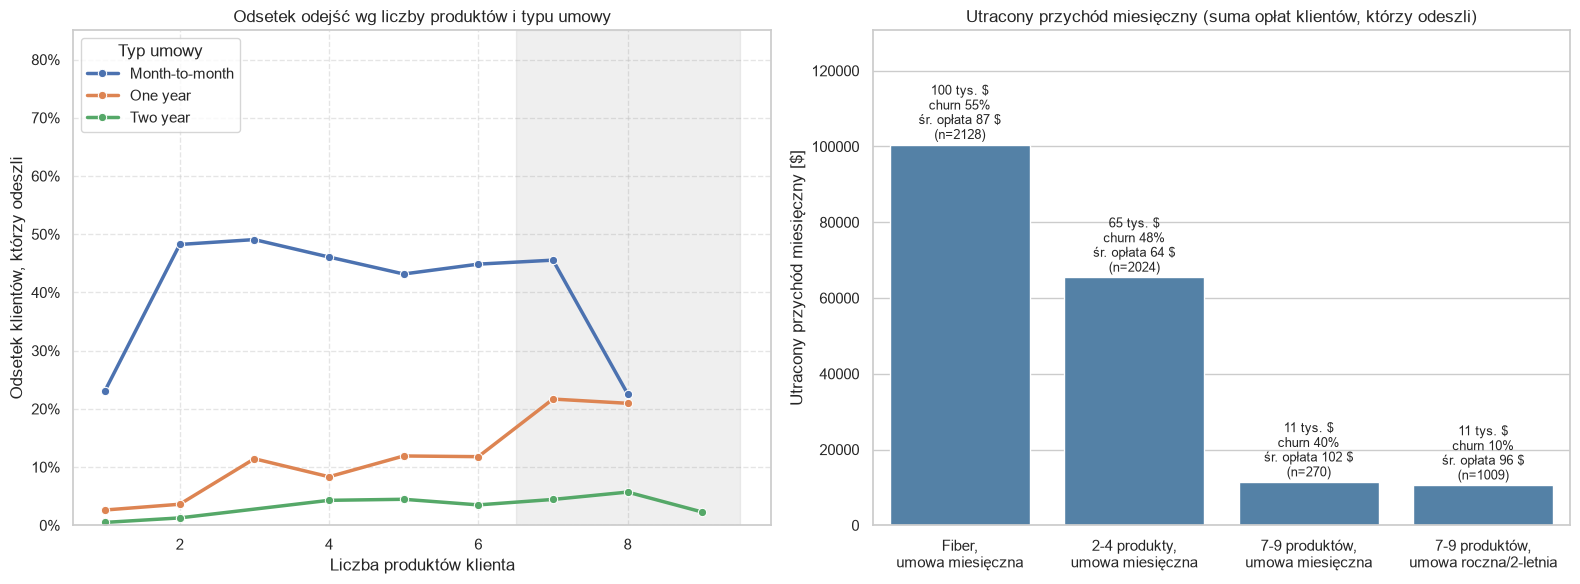

,segment,n,churn_rate,avg_fee,lost_revenue
0,"Fiber,\numowa miesięczna",2128,0.546,87.021,100482.0
1,"2-4 produkty,\numowa miesięczna",2024,0.478,63.636,65448.5
2,"7-9 produktów,\numowa miesięczna",270,0.404,101.744,11399.7
3,"7-9 produktów,\numowa roczna/2-letnia",1009,0.102,96.005,10568.9


<Figure size 640x480 with 0 Axes>

In [18]:
by_contract = (
    df.groupby(["n_products", "Contract"], observed=True)["Churn"]
    .agg(churn_rate="mean", n="size")
    .reset_index()
)
by_contract = by_contract[by_contract["n"] >= 30]  
mtm = df["Contract"] == "Month-to-month"
segments = {
    "Fiber,\numowa miesięczna": (df["InternetService"] == "Fiber optic") & mtm,
    "2-4 produkty,\numowa miesięczna": df["n_products"].between(2, 4) & mtm,
    "7-9 produktów,\numowa miesięczna": (df["n_products"] >= 7) & mtm,
    "7-9 produktów,\numowa roczna/2-letnia": (df["n_products"] >= 7) & ~mtm,
}
rows = []
for name, mask in segments.items():
    d = df[mask]
    rows.append({
        "segment": name,
        "n": len(d),
        "churn_rate": d["Churn"].mean(),
        "avg_fee": d["MonthlyCharges"].mean(),
        "lost_revenue": d.loc[d["Churn"] == 1, "MonthlyCharges"].sum(),
    })
seg = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(
    data=by_contract, x="n_products", y="churn_rate", hue="Contract",
    hue_order=["Month-to-month", "One year", "Two year"],
    marker="o", linewidth=2.5, ax=axes[0],
)
axes[0].axvspan(6.5, 9.5, color="grey", alpha=0.12)   
axes[0].set_title("Odsetek odejść wg liczby produktów i typu umowy")
axes[0].set_xlabel("Liczba produktów klienta")
axes[0].set_ylabel("Odsetek klientów, którzy odeszli")
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[0].set_ylim(0, 0.85)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(title="Typ umowy")

sns.barplot(data=seg, x="segment", y="lost_revenue", color="steelblue", ax=axes[1])
for i, r in seg.iterrows():
    axes[1].text(
        i, r["lost_revenue"] + 1500,
        f"{r['lost_revenue']/1000:.0f} tys. $\nchurn {r['churn_rate']:.0%}\nśr. opłata {r['avg_fee']:.0f} $\n(n={int(r['n'])})",
        ha="center", fontsize=9,
    )
axes[1].set_title("Utracony przychód miesięczny (suma opłat klientów, którzy odeszli)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Utracony przychód miesięczny [$]")
axes[1].set_ylim(0, seg["lost_revenue"].max() * 1.3)

plt.tight_layout()
plt.show()
plt.savefig('fiber_churn.png', dpi=300)
seg.round(3)

Przy umowie miesięcznej churn utrzymuje się na poziomie ok. $43–49\%$ aż do 7 produktów, a spada dopiero przy 8 (przy 9 produktach jest za mało klientów na umowie miesięcznej, aby go pokazać). **Umowy roczna i dwuletnia chronią w każdej grupie liczby produktów.** W grupie 7-9 produktów klienci na umowie miesięcznej odchodzą w $40\%$ przypadków (n=270, średnia opłata ok. 102 USD), a z umową dwuletnią w $4\%$. Pojedynczy klient z tej grupy jest bardzo cenny, ale **największy łączny utracony przychód pochodzi z klientów Fiber na umowie miesięcznej (ok. 100 tys. USD miesięcznie, churn 55%) i z grupy 2-4 produktów na umowie miesięcznej (ok. 65 tys. USD)**.

**Sposób płatności a churn**

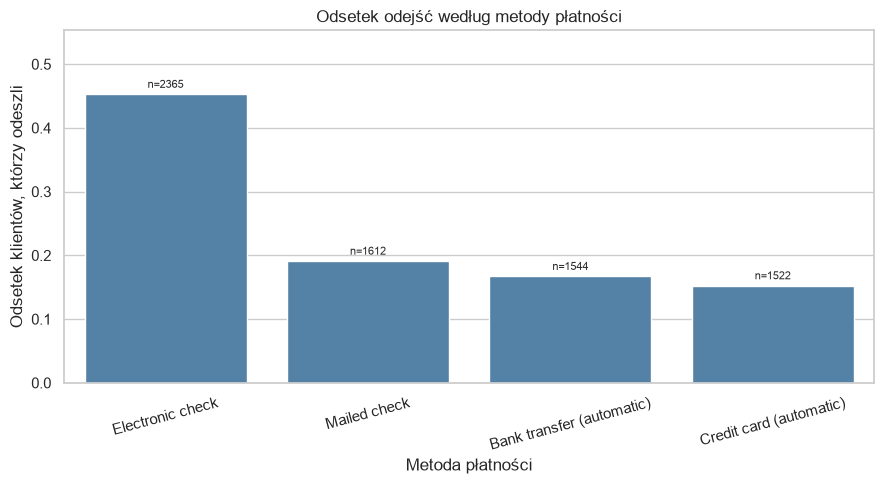

In [19]:
pay_stats = (
    df.groupby("PaymentMethod")["Churn"]
    .agg(churn_rate="mean", n="size")
    .sort_values("churn_rate", ascending=False)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(data=pay_stats, x="PaymentMethod", y="churn_rate",
            color="steelblue", ax=ax)
for i, row in pay_stats.iterrows():
    ax.text(i, row["churn_rate"] + 0.01, f"n={row['n']}", ha="center", fontsize=8)

ax.set_title("Odsetek odejść według metody płatności")
ax.set_xlabel("Metoda płatności")
ax.set_ylabel("Odsetek klientów, którzy odeszli")
ax.set_ylim(0, pay_stats["churn_rate"].max() + 0.1)
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig('platnosc_churn.png', dpi=300)

plt.show()

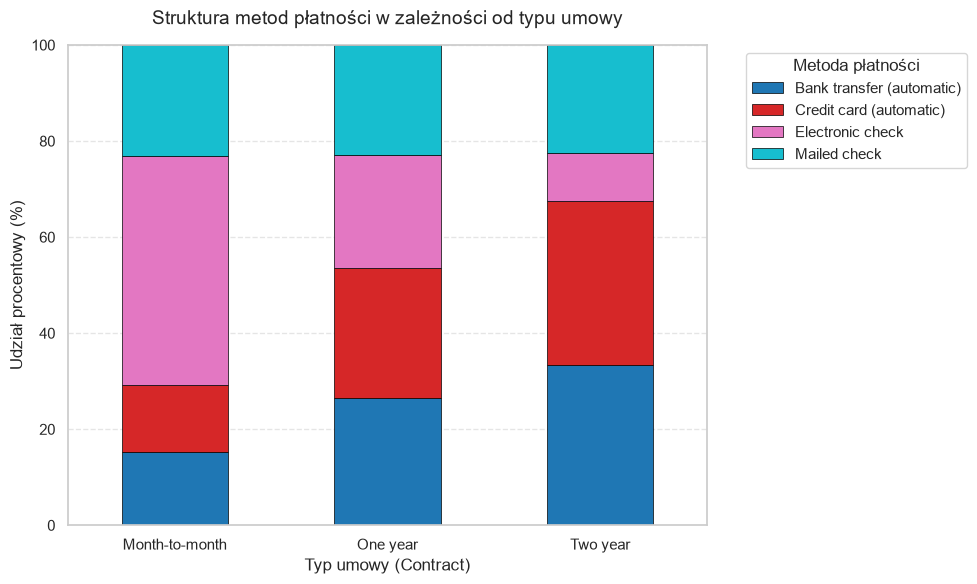

In [20]:
ct_pct = pd.crosstab(df['Contract'], df['PaymentMethod'], normalize='index') * 100

ct_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='tab10',
    edgecolor='black',
    linewidth=0.5,
)

plt.title(
    'Struktura metod płatności w zależności od typu umowy', fontsize=14, pad=15
)
plt.xlabel('Typ umowy (Contract)', fontsize=12)
plt.ylabel('Udział procentowy (%)', fontsize=12)
plt.legend(title='Metoda płatności', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.ylim(0, 100)

plt.tight_layout()
plt.savefig('platnosc_umowa.png', dpi=300)

plt.show()

Widoczna jest korelacja - większość klientów *krótkoterminowych* płaci za pośrednictwem *Electronic check*, czyli metodą o najwyższym odsetku odejść. Krzyżują się tu więc dwie grupy o podwyższonym ruzyku churnu. Klienci tego typu mogą bez probemu zrezygnować, z różnych powodów, a należy pamiętać, że w grupie krótkoterminowej są osoby płacące najwyższe rachunki miesięczne. W umowach długoterminowych typy płatności są z kolei dużo stabilniejsze, z przewagą płatności automatycznych.

Wniosek - należy ukierunkować działania na to, aby klienci krótkoterminowi przeszli na płatności automatyczne oraz zmienili swoje umowy na roczne lub dwuletnie.

## Podsumowanie

**Ogólna charakterystyka danych**
Zbiór liczy $7,043$ klientów, z czego *Churn Rate* wynosi $26,5\%$. Oznacza to, że będą potrzebne odpowiednio dobrane metryki oraz kontrola niezbalansowania klas.

**Główne czynniki ryzyka**

- *Klienci na umowach miesięcznych (Month-to-month)*: odsetek odejść w tej grupie to $42.7\%$. Brak długoterminowego zobowiązania ułatwia natychmiastową rezygnację.

- *Nowi klienci w fazie wdrożeniowej ($0–6$ miesięcy)*: aż $52.9\%$ rezygnacji następuje na samym początku współpracy, co stanowi $42\%$ wszystkich odejść. Możliwe, że oznacza to kryzys w procesie onboardingu i dopasowania oczekiwań klienta do rzeczywistości.

- *Użytkownicy Fiber optic bez dodatków*: Fiber optic to najdroższa pojedyncza usługa w ofercie, a klienci korzystający z niej rezygnują w $41.9\%$ przypadków – głównie wtedy, gdy posiadają tylko 2–3 produkty, przez co odczuwają wysokie koszty jako nieadekwatne do wartości.

- *Osoby płacące Electronic check*: wskaźnik rezygnacji w tej grupie wynosi $45.3\%$ (w porównaniu do $15\text{--}19\%$ przy innych formach płatności).

- *Seniorzy (szczególnie mieszkający samotnie)*: to najryzykowniejszy segment z odsetkiem odejść sięgającym aż 49.2% u osób żyjących w pojedynkę. 

- *Osoby niebędące seniorami - samotne, bez dzieci*: wysoki wskaźnik rezygnacji ($31.2\%$) prawdopodobnie wiąże się z brakiem więzów rodzinnych i masowym wybieraniem umów miesięcznych, co ułatwia natychmiastową ucieczkę do konkurencji.

**Czynniki lojalizujące klientów**

- *Pakiety usług*: Istnieje silna korelacja między liczbą posiadanych usług a lojalnością. Klienci z rozbudowanym ekosystemem (7-9 produktów) mają zaledwie $5\text{--}12\%$ szans na odejście. Z kolei klienci z 2-3 produktami są w strefie najwyższego ryzyka ($31\text{--}45\%$). Klienci z dużą liczbą usług mają zwykle długi staż i umowę dwuletnią, więc liczba usług może być markerem lojalności, a nie jej przyczyną. 
  
- *Usługi dodatkowe o charakterze opiekuńczym*: wśród klientów z internetem ci, którzy mają wsparcie techniczne (TechSupport) lub zabezpieczenia online (OnlineSecurity), rezygnują na poziomie ok. $15\%$, a ci bez nich ok. $42\%$.
  
- *Długoterminowe umowy*: umowy roczne ($11.3\%$) i dwuletnie ($2.8\%$ churnu) są niezwykle skuteczne jako zabezpieczenie przeciwko rezygnacji.

**Strategiczne rekomendacje biznesowe**
Skuteczność rekomendacji należy zweryfikować testem A/B, bo EDA pokazuje korelacje, a nie przyczyny.

 - *Program dla nowych klientów*: Wdrożenie specjalnej opieki i wsparcia w pierwszych 6 miesiącach współpracy.
   
 - *Dosprzedaż produktów*: skierowanie ofert pakietowych do klientów posiadających 2-3 usługi, dobudowując do nich pakiety bezpieczeństwa i wsparcia technicznego w celu obniżenia odczuwalności kosztów i domknięcia ekosystemu.

 - *Zmiana na umowy długoterminowe*: zachęcanie klientów z umowami krótkoterminowami do przejścia na umowy roczne/dwuletnie (np. poprzez rabaty).

 - *Zachęcanie do automatycznych płatności*: odchodzenie od czeków elektronicznych na rzecz poleceń zapłaty / kart kredytowych.

 - *Dla nowych umów, eliminacja umów krótkoterminowych dla pakietów z 7, 8 i 9 pakietami*: ponieważ w tej grupie klienci bez zobowiązania odchodzą w $40\%$ przypadków, a z umową dwuletnią w $4\%$.

 - *Priorytet: Fiber na umowie miesięcznej*: to największy łączny utracony przychód (ok. 100 tys. USD miesięcznie, churn $55\%$). Należy jak najszybciej wdrożyć działania mające na celu zachęcenie użytkowników na zmianę typu umowy.

 - *Audyt Fiber Optic*: to najbardziej problematyczny z produktów, więc należy przeprowadzić audyt, który powinien odpowiedzieć jednoznacznie, czemu odchodzących klientów z tą uslugą jest tak wielu oraz jak przedstawia się na tle konkurencji.
